# Coherence transfer pathways: worked examples

A cookbook for the `ctps` module, in two parts: ten worked cases, from a
double-quantum filter to crusher optimisation, and then the checks behind the
module's tests, repeated as runnable examples so that the evidence is on the
page. [Coherence transfer pathways](ctps.ipynb) explains the module and its
conventions; this guide assumes it. The companion notebook is
[`notebooks/ctps-examples.ipynb`](ctps-examples.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/ctps-examples.ipynb)).

*Generated from [`docs/ctps-examples.md`](../ctps-examples.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

Worked cases

1. [A double-quantum filter](#A-double-quantum-filter)
2. [Spin echo: leakage versus flip-angle error](#Spin-echo:-leakage-versus-flip-angle-error)
3. [Stimulated echo: echo and anti-echo](#stimulated-echo-echo-and-anti-echo)
4. [A NOESY-sized enumeration: 352,947 pathways](#A-NOESY-sized-enumeration:-352,947-pathways)
5. [HSQC with two nuclei](#HSQC-with-two-nuclei)
6. [MQMAS: nested versus cogwheel](#MQMAS:-nested-versus-cogwheel)
7. [5Q3QMAS and the HCL construction](#5Q3QMAS-and-the-HCL-construction)
8. [Multi-echo trains: 2n + 1 steps](#Multi-echo-trains:-2n-+-1-steps)
9. [Cogwheel plus gradients](#Cogwheel-plus-gradients)
10. [MRS crushers and fixed-length cycles](#MRS-crushers-and-fixed-length-cycles)

The checks behind the tests

11. [The 1998 table, row by row](#The-1998-table,-row-by-row)
12. [Every published cogwheel cycle](#Every-published-cogwheel-cycle)
13. [The 22 solutions at N = 23](#The-22-solutions-at-N-=-23)
14. [The N_opt grid of Hughes 2004](#The-N_opt-grid-of-Hughes-2004)
15. [The pulse model against exact rotations](#The-pulse-model-against-exact-rotations)
16. [Engine self-consistency](#Engine-self-consistency)
17. [The optimiser against the MRS papers](#The-optimiser-against-the-MRS-papers)
18. [Running the tests and rebuilding this notebook](#Running-the-tests-and-rebuilding-this-notebook)

In [1]:
import itertools
import json
import time
from pathlib import Path

import numpy as np

from ctps import AllowedOrders, Nucleus, Period, PhaseCycle, Pulse, Sample, Sequence, simulate
from ctps import coverage, find_cycle, hcl_cycle

ms = 1e-3
H = Nucleus("1H")

## A double-quantum filter

Three 90° pulses; the third one converts double-quantum coherence (`p = ±2`)
into observable `−1`, a jump `Δp₃ = −3` or `+1`. The four-step cycle
`φ₃ = 0, 90, 180, 270` with receiver `0, 270, 180, 90` keeps `Δp₃ ≡ 1 (mod 4)`
and rejects the single-quantum pathways (`Δp₃ = −1` or `0`, through `p₂ = 0`
or `±1`). The first pulse acts on `z` magnetisation, so period 1 is limited
to `±1`. `simulate` enumerates every pathway the allowed orders permit,
weights it and ranks it; `table()` lists the factors; `leakage()` counts the
unwanted pathways above a fraction of the strongest wanted one:

In [2]:
dqf = Sequence.simple(n_pulses=3, p_max=2, periods={1: [-1, 1]})
four = PhaseCycle.explicit([[0], [0], [0, 1, 2, 3]], receiver=[0, 3, 2, 1], base=4)
wanted_dqf = [(0, 1, 2, -1), (0, -1, 2, -1), (0, 1, -2, -1), (0, -1, -2, -1)]
dq = simulate(dqf, four, wanted=wanted_dqf)
print(f"{dq.n_enumerated} pathways, {len(dq)} with a nonzero phase-cycle factor, {dq.leakage(0.01)} unwanted above 1%")
for row in dq.table():
    print(row["pathway"], "wanted" if row["wanted"] else "      ", f"pc {row['pc']:.2f}")

10 pathways, 4 with a nonzero phase-cycle factor, 0 unwanted above 1%
[0, -1, -2, -1] wanted pc 1.00
[0, -1, 2, -1] wanted pc 1.00
[0, 1, -2, -1] wanted pc 1.00
[0, 1, 2, -1] wanted pc 1.00


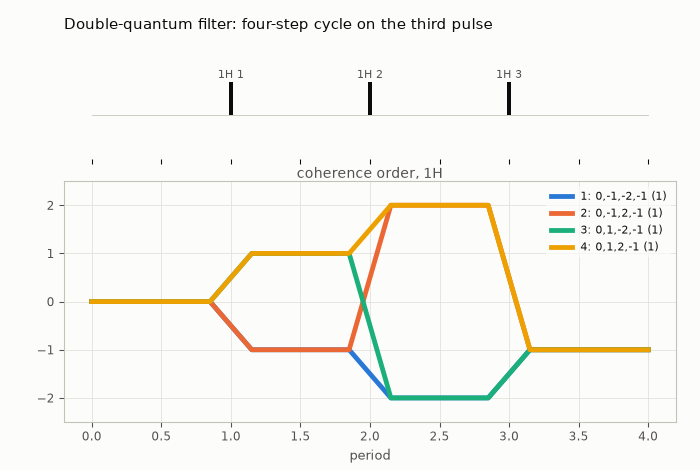

In [3]:
from ctps.plot import plot_pathways

plot_pathways(dq, top=8, title="Double-quantum filter: four-step cycle on the third pulse")

A two-step cycle on the same pulse, `φ₃ = 0, 180` with receiver `0, 180`,
only keeps `Δp₃` odd, so the pathways through `p₂ = 0` survive too:

In [4]:
two = PhaseCycle.explicit([[0], [0], [0, 2]], receiver=[0, 2], base=4)
dq2 = simulate(dqf, two, wanted=wanted_dqf)
print(f"two steps: {len(dq2)} pathways pass, {dq2.leakage(0.01)} unwanted above 1%")
print(sorted({tuple(int(v) for v in p) for p in dq2.orders[~dq2.wanted]}))

two steps: 6 pathways pass, 2 unwanted above 1%
[(0, -1, 0, -1), (0, 1, 0, -1)]


## Spin echo: leakage versus flip-angle error

The Hahn echo of the 2000 paper: a 90° pulse and a 180° pulse `β` short of π.
The inverted pathway `0, 1, −1` passes with weight 1; the non-inverted
`0, −1, −1` leaks with weight `(β/2)²` and the pathway through `z`,
`0, 0, −1`, with `√2 β/2`, as the leading terms of the rotation matrix
elements give. Scanning `β` with `simulate` shows the quadratic and linear
scalings:

In [5]:
betas = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.3])
leak = {(0, -1, -1): [], (0, 0, -1): []}
for beta in betas:
    echo = Sequence(
        nuclei=(H,),
        pulses=(Pulse("1H"), Pulse("1H", "imperfect_180", beta=beta)),
        periods=(Period(), Period(), Period()),
        allowed={"1H": AllowedOrders.standard(1, 3)},
    )
    one_step = PhaseCycle.explicit([[0], [0]], receiver=[0])
    result = simulate(echo, one_step, epsilon=0, cutoff=0)
    rows = {tuple(int(v) for v in r): float(result.amplitude[i]) for i, r in enumerate(result.orders)}
    for path in leak:
        leak[path].append(rows[path])
for path, values in leak.items():
    print(path, " ".join(f"{v:.2e}" for v in values))
print("ratio of successive values at beta 0.1 and 0.2:", {p: round(v[4] / v[3], 2) for p, v in leak.items()})

(0, -1, -1) 2.50e-05 1.00e-04 6.25e-04 2.50e-03 1.00e-02 2.25e-02
(0, 0, -1) 7.07e-03 1.41e-02 3.54e-02 7.07e-02 1.41e-01 2.12e-01
ratio of successive values at beta 0.1 and 0.2: {(0, -1, -1): 4.0, (0, 0, -1): 2.0}


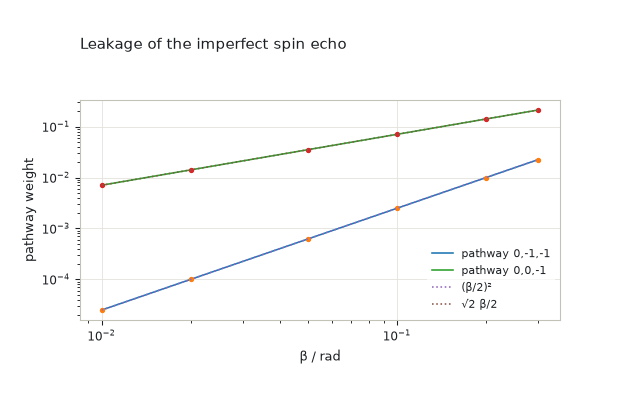

In [6]:
import plotly.graph_objects as go

fig = go.Figure()
for path, values in leak.items():
    fig.add_scatter(x=betas, y=values, mode="lines+markers", name=f"pathway {','.join(map(str, path))}")
fig.add_scatter(x=betas, y=(betas / 2) ** 2, mode="lines", line={"dash": "dot"}, name="(β/2)²")
fig.add_scatter(x=betas, y=np.sqrt(2) * betas / 2, mode="lines", line={"dash": "dot"}, name="√2 β/2")
fig.update_layout(title="Leakage of the imperfect spin echo", xaxis_title="β / rad", yaxis_title="pathway weight",
                  xaxis_type="log", yaxis_type="log", width=640, height=400)
fig

## Stimulated echo: what the spoilers do

The 1998 Fig. 4 sequence (built here as in the `ctps` guide, pulses 2 and 5
as perfect 180° pulses) stores magnetisation along `z` during the long mixing
period 3 and refocuses the pathway pair `0, ∓1, ±1, 0, ±1, ∓1, 0, −1` with its
bipolar gradient pairs. The transverse spoilers in periods 3 and 6 are there
for the pathways that carry coherence through those periods; comparing the
sequence with and without them shows what they remove:

In [7]:
def stimulated_echo(spoilers: bool = True) -> Sequence:
    periods = [
        Period(),
        Period.with_gradient(2 * ms, "z", 0.25, 1 * ms),
        Period.with_gradient(2 * ms, "z", -0.25, 1 * ms),
        Period.with_gradient(50 * ms, "x", 0.025, 1 * ms) if spoilers else Period(50 * ms),
        Period.with_gradient(2 * ms, "z", 0.25, 1 * ms),
        Period.with_gradient(2 * ms, "z", -0.25, 1 * ms),
        Period.with_gradient(0.0, "y", 0.025, 1 * ms) if spoilers else Period(),
        Period(),
    ]
    allowed = AllowedOrders.standard(3, 8).only(1, [-1, 0, 1])
    pulses = tuple(Pulse("1H", "perfect_180" if j in (1, 4) else "free") for j in range(7))
    return Sequence((H,), pulses, tuple(periods), {"1H": allowed}, Sample(5 * ms, 2.5 * ms), diffusion=7e-10)


ste_cycle = PhaseCycle.explicit(
    [[0, 0, 1, 1, 2, 2, 3, 3], [1, 2, 2, 3, 3, 0, 0, 1], [0], [2, 2, 3, 3], [3, 3, 0, 0], [2], [0]],
    receiver=[0, 2, 0, 2, 2, 0, 2, 0],
    base=4,
)
wanted_ste = [(0, -1, 1, 0, 1, -1, 0, -1), (0, 1, -1, 0, -1, 1, 0, -1)]
for spoilers in (False, True):
    result = simulate(stimulated_echo(spoilers), ste_cycle, wanted=wanted_ste)
    print(f"spoilers {spoilers!s:5}: {len(result)} pathways above threshold, {result.leakage(0.01)} unwanted above 1%, "
          f"strongest unwanted {result.amplitude[~result.wanted][0]:.3f}: {result.orders[~result.wanted][0].tolist()}")

spoilers False: 518 pathways above threshold, 68 unwanted above 1%, strongest unwanted 0.515: [0, -1, 1, 0, 1, -1, -3, -1]
spoilers True : 372 pathways above threshold, 8 unwanted above 1%, strongest unwanted 0.012: [0, -1, 1, 0, 1, -1, -1, -1]


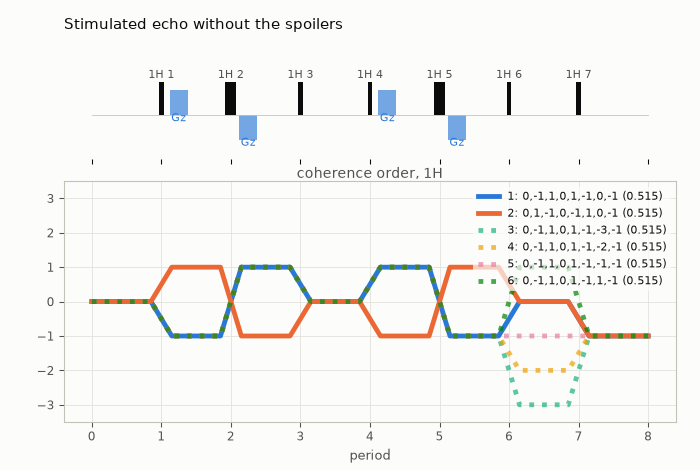

In [8]:
plot_pathways(simulate(stimulated_echo(False), ste_cycle, wanted=wanted_ste), top=6, title="Stimulated echo without the spoilers")

## A NOESY-sized enumeration: 352,947 pathways

Eight pulses, orders up to ±3 after the first period, as in the 1998
2Q-NOESY example: `3 · 7⁶ = 352,947` pathways, with the gradient scheme and
delays of that figure and an eight-step cycle on the first and last pulses.
The enumeration and the weighting are vectorised over chunks of pathways and
`workers=` spreads the chunks over processes; the point here is scale and
speed:

In [9]:
delays = [15, 15, 15, 15, 7.5, 1.35, 1.35, 1.35]
gradients = {1: ("x", 0.05), 2: ("z", 0.05), 3: ("z", -0.05), 4: ("z", 0.2)}
periods = [Period()]
for i in range(1, 9):
    if i in gradients:
        periods.append(Period.with_gradient(delays[i - 1] * ms, *gradients[i], 1.25 * ms))
    else:
        periods.append(Period(delays[i - 1] * ms))
noesy = Sequence(
    (H,),
    tuple(Pulse("1H") for _ in range(8)),
    tuple(periods),
    {"1H": AllowedOrders.standard(3, 9).only(1, [-1, 0, 1])},
    Sample(5 * ms, 2.5 * ms),
    diffusion=2e-9,
)
noesy_cycle = PhaseCycle.explicit(
    [[0, 0, 0, 0, 2, 2, 2, 2], [0], [0], [0], [0], [0], [0], [0, 3, 2, 1]], receiver=[0, 2, 0, 2, 2, 0, 2, 0], base=4
)
for workers in (1, 2):
    start = time.perf_counter()
    result = simulate(noesy, noesy_cycle, cutoff=1e-4, workers=workers)
    print(f"{result.n_enumerated} pathways, {len(result)} above 1e-4, {time.perf_counter() - start:.2f} s with {workers} worker(s)")
print("strongest:", [tuple(int(v) for v in o) for o in result.orders[:2]], [round(float(a), 4) for a in result.amplitude[:2]])

352947 pathways, 2548 above 1e-4, 0.15 s with 1 worker(s)
352947 pathways, 2548 above 1e-4, 0.14 s with 2 worker(s)
strongest: [(0, -1, 0, 0, 0, -3, -3, -3, -1), (0, -1, 0, 0, 0, -3, -3, 1, -1)] [0.0057, 0.0057]


## HSQC with two nuclei

The nine-pulse HSQC of the 1998 Fig. 9, with proton orders up to ±2, carbon
±1, perfect 180° pulses, the four-step cycle on the two carbon 90° pulses
(`x, −x` and `x, x, −x, −x`, receiver `x, −x, −x, x`) and a gradient pair,
0.199 T/m on carbon coherence during the evolution and 0.05 T/m on proton
coherence before detection, in the ratio of the gyromagnetic ratios so that
one member of the echo/anti-echo pair refocuses. Each nucleus keeps its own
order; the explorer shows both and their sum:

In [10]:
C = Nucleus("13C")
kinds = ["90", "180", "180", "90", "90", "90", "90", "180", "180"]
on = ["1H", "1H", "13C", "1H", "13C", "13C", "1H", "1H", "13C"]
periods = [Period() for _ in range(10)]
periods[5] = Period.with_gradient(1.85 * ms, "z", 0.199, 1 * ms)  # during the evolution, on carbon coherence
periods[8] = Period.with_gradient(1.85 * ms, "z", 0.05, 1 * ms)  # before detection, on proton coherence
hsqc = Sequence(
    (H, C),
    tuple(Pulse(n, "perfect_180" if k == "180" else "free", label=f"{n} {k}") for n, k in zip(on, kinds)),
    tuple(periods),
    {"1H": AllowedOrders.standard(2, 10), "13C": AllowedOrders.standard(1, 10, end=[0])},
    Sample(5 * ms, 2.5 * ms),
)
hsqc_cycle = PhaseCycle.explicit([[0]] * 4 + [[0, 2], [0, 0, 2, 2], [0], [0], [0]], receiver=[0, 2, 2, 0], base=4)
hsqc_wanted = [(0, 1, -1, -1, 0, 1, 0, 1, -1, -1), (0, 1, -1, -1, 0, -1, 0, 1, -1, -1)]
hsqc_result = simulate(hsqc, hsqc_cycle, wanted=hsqc_wanted)
print(f"{hsqc_result.n_enumerated} pathways, {len(hsqc_result)} above threshold, {hsqc_result.leakage(0.05)} unwanted above 5%")
for row in hsqc_result.table()[:4]:
    print(row["pathway"], "wanted" if row["wanted"] else "      ", f"total {row['total']:.3f}  grad {row['grad']:.3f}")

75 pathways, 50 above threshold, 4 unwanted above 5%
[0, 1, -1, -1, 0, 1, 0, 1, -1, -1] wanted total 0.999  grad 0.999
[0, -2, 2, 2, 0, 1, 0, 1, -1, -1]        total 0.999  grad 0.999
[0, -1, 1, 1, 0, 1, 0, 1, -1, -1]        total 0.999  grad 0.999
[0, 0, 0, 0, 0, 1, 0, 1, -1, -1]        total 0.999  grad 0.999


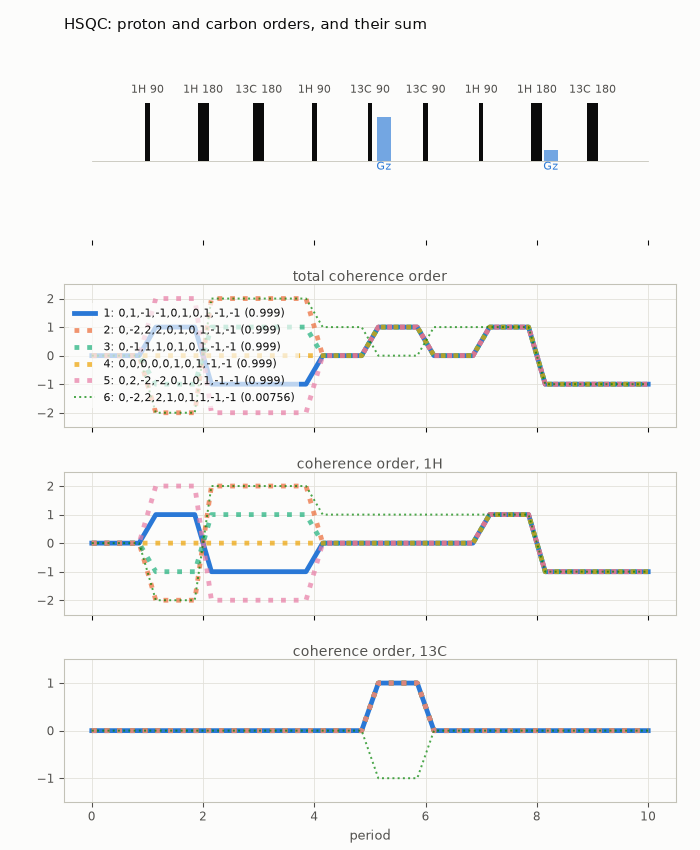

In [11]:
plot_pathways(hsqc_result, top=6, title="HSQC: proton and carbon orders, and their sum")

## MQMAS: nested versus cogwheel

Triple-quantum MAS on a spin 3/2 selects `0, +3, +1, −1`. The nested cycle
needs 7 × 5 = 35 steps; `PhaseCycle.nested` builds it from the per-pulse
lists (pulse 0 stepping fastest), and the receiver list is written out.
Levitt's `COG23(0,3,4;14)` does the same in 23. The 2003 paper's variants
shorten the cycle further by restricting the orders: with odd orders only
and a perfect detector, 11 steps suffice; with the detector also accepting
`0` and `+1`, 29 (all orders) or 19 (odd orders). `simulate` verifies each:
every unwanted pathway must have `pc = 0`:

In [12]:
mqmas = Sequence.simple(3, 3)
# the nested cycle: 7 steps on pulse 1 (selecting Δp = +3) nested with 5 on pulse 3 (Δp = -2), on the common base 35
levels = PhaseCycle.nested([[5 * k for k in range(7)], [0], [7 * k for k in range(5)]], receiver=[0], base=35)
rec = [(-3 * levels.phases[0][m] + 2 * levels.phases[2][m]) % 35 for m in range(35)]  # φ_rec = -Σ Δp_j φ_j for the wanted pathway
nested35 = PhaseCycle.explicit(levels.phases, receiver=rec, base=35)


def verify(sequence, cycle, wanted):
    result = simulate(sequence, cycle, wanted=wanted, epsilon=0, cutoff=0)
    unwanted = np.abs(result.pc[~result.wanted])
    print(f"{cycle.cog_string():>40}: {cycle.steps:3d} steps, {result.wanted.sum()} wanted at |pc| = 1, "
          f"largest unwanted |pc| = {unwanted.max() if unwanted.size else 0:.1e}")


verify(mqmas, nested35, [(0, 3, 1, -1)])
verify(mqmas, PhaseCycle.cogwheel(23, [0, 3, 4], 14), [(0, 3, 1, -1)])
verify(Sequence.simple(3, 3, orders=[-3, -1, 0, 1, 3]), PhaseCycle.cogwheel(11, [3, 1, 0], 4), [(0, 3, 1, -1)])
verify(Sequence.simple(3, 3, end=[-1, 0, 1]), PhaseCycle.cogwheel(29, [9, 11, 2], 28), [(0, 3, 1, -1)])
verify(Sequence.simple(3, 3, end=[-1, 0, 1], orders=[-3, -1, 0, 1, 3]), PhaseCycle.cogwheel(19, [3, 8, 1], 9), [(0, 3, 1, -1)])

       explicit cycle, 35 steps, base 35:  35 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 1.1e-16
                         COG23(0,3,4;14):  23 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 1.3e-16
                          COG11(3,1,0;4):  11 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 7.3e-17
                        COG29(9,11,2;28):  29 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 1.2e-16
                          COG19(3,8,1;9):  19 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 1.5e-16


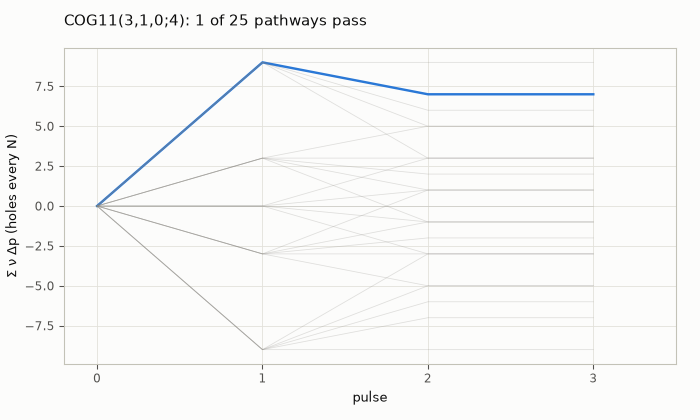

In [13]:
from ctps.plot import plot_selection_diagram

plot_selection_diagram(PhaseCycle.cogwheel(11, [3, 1, 0], 4), Sequence.simple(3, 3, orders=[-3, -1, 0, 1, 3]), wanted=[(0, 3, 1, -1)])

## 5Q3QMAS and the HCL construction

For `0, +5, +3, +1, −1` on a spin 5/2 the Hughes–Carravetta–Levitt formula
gives 201 steps (nested: 693). Restricting the orders shortens it, as the 2003
paper shows: odd orders only give `COG55`, and fixing the last two orders at
`+1, −1` gives `COG29`. Verification by `simulate` is instant where a search
up to 201 would take a while:

In [14]:
print("HCL:", hcl_cycle([5, 3, 1], [5, 5, 5]).cog_string())
verify(Sequence.simple(4, 5), PhaseCycle.cogwheel(201, [157, 142, 3, 0], 108), [(0, 5, 3, 1, -1)])
verify(Sequence.simple(4, 5, orders=[-5, -3, -1, 0, 1, 3, 5]), PhaseCycle.cogwheel(55, [33, 30, 1, 0], 7), [(0, 5, 3, 1, -1)])
verify(Sequence.simple(4, 5, orders=[-5, -3, -1, 0, 1, 3, 5], periods={3: [1], 4: [-1]}), PhaseCycle.cogwheel(29, [3, 1, 0, 0], 16), [(0, 5, 3, 1, -1)])

HCL: COG201(0,15,20,23;116)
                 COG201(157,142,3,0;108): 201 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 1.3e-16
                      COG55(33,30,1,0;7):  55 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 1.5e-16
                       COG29(3,1,0,0;16):  29 steps, 1 wanted at |pc| = 1, largest unwanted |pc| = 1.2e-16


## Multi-echo trains: 2n + 1 steps

A preparation pulse followed by `n` refocusing pulses, orders `0, ±1`, wanted
pathway alternating `+1, −1`: nested cycling needs `5^(n/2)` steps (`n` even),
a cogwheel cycle `2n + 1` with winding numbers alternating 0 and 1 (Levitt
2002). `find_cycle` finds them:

In [15]:
for n in (3, 5):
    train = Sequence.simple(n + 1, 1)
    wanted = [tuple([0] + [(-1) ** k for k in range(n + 1)])]
    found = find_cycle(train, wanted)
    print(f"{n} refocusing pulses: {found.best.cog_string()}, nested would need {5 ** ((n + 1) // 2)} steps")

3 refocusing pulses: COG7(0,1,0,1;4), nested would need 25 steps
5 refocusing pulses: COG11(0,1,0,1,0,1;6), nested would need 125 steps


## Cogwheel plus gradients

The one-spin PFG stimulated echo of the 2003 paper (orders fixed at 0 after
pulses 3 and 6) has the cogwheel cycle `COG8(0,7,0,0,1,0,0;4)`. With the
bipolar gradients of the 1998 example in place, most unwanted pathways are
already attenuated, so the cycle only has to reject the rest:
`pathway_weights` returns every pathway's gradient × diffusion × pulse
weight in enumeration order, and `find_cycle(..., weights=g, tolerance=...)`
accepts a cycle once the summed weight of the surviving unwanted pathways is
below the tolerance:

In [16]:
from ctps.optimize import pathway_weights

pfg = Sequence.simple(7, 1, periods={3: [0], 6: [0]})
wanted_pfg = [(0, -1, 1, 0, 1, -1, 0, -1), (0, 1, -1, 0, -1, 1, 0, -1)]
print("phase cycling alone:", find_cycle(pfg, wanted_pfg).best.cog_string())
with_gradients = Sequence(
    pfg.nuclei, pfg.pulses, stimulated_echo().periods[:3] + stimulated_echo().periods[3:], pfg.allowed, Sample(5 * ms, 2.5 * ms)
)
orders, g = pathway_weights(with_gradients)
print(f"{len(orders)} pathways; {int((g < 1e-3).sum())} already below 1e-3 from the gradients")
weighted = find_cycle(with_gradients, wanted_pfg, weights=g, tolerance=0.05)
print(f"with the gradients taken into account: {weighted.best.cog_string()}, surviving weight {weighted.best.residual:.3f}")

phase cycling alone: COG8(0,1,0,0,7,0,0;4)
81 pathways; 10 already below 1e-3 from the gradients
with the gradients taken into account: COG4(0,1,0,0,0,0,0;2), surviving weight 0.026


## MRS crushers and fixed-length cycles

PRESS and sLASER from the DOTCOPS papers: `crusher_scheme` maximises the
smallest and the mean dephasing of the unwanted pathways (the k-space radius
`|Σ p_i X_i|`, with the wanted pathway refocused and per-crusher bounds), and
`coverage` finds, for a fixed number of steps, the cogwheel cycle that cancels
the most unwanted pathways. The chosen cycle goes to the spectrometer through
`bruker_phase_program` or a `phase_table`, and the pathway list to a file:

In [17]:
from ctps.io import bruker_phase_program, phase_table, write_csv
from ctps.optimize import crusher_scheme

press = Sequence.simple(3, 1)
bounds = np.array([[0, 0, 0], [1, 1, 1], [2, 2, 2], [1, 1, 1]], dtype=float)
scheme = crusher_scheme(press, [(0, -1, 1, -1)], bounds=bounds, starts=40)
print(f"PRESS crushers: min D = {scheme['min_D']:.3f}, mean D = {scheme['mean_D']:.3f}")
print(np.round(scheme["areas"], 2))
slaser = Sequence.simple(5, 1)
for N in (8, 16):
    best = coverage(slaser, [(0, -1, 1, -1, 1, -1)], N).best
    print(f"sLASER, {N} steps: {best.cog_string()}, {best.survivors} unwanted pathways survive")
print(bruker_phase_program(best.cycle))
print(phase_table(best.cycle)[1])
chosen = simulate(slaser, best.cycle, wanted=[(0, -1, 1, -1, 1, -1)])
write_csv(chosen, Path("slaser_pathways.csv"))
print(Path("slaser_pathways.csv").read_text().splitlines()[:2])
Path("slaser_pathways.csv").unlink()

PRESS crushers: min D = 1.732, mean D = 3.155
[[ 0.  0.  0.]
 [ 1. -1. -1.]
 [ 2. -2. -0.]
 [ 1. -1.  1.]]
sLASER, 8 steps: COG8(0,1,0,1,0;4), 1 unwanted pathways survive
sLASER, 16 steps: COG16(0,1,0,1,0;12), 0 unwanted pathways survive
ph1=(16) 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
ph2=(16) 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
ph3=(16) 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
ph4=(16) 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
ph5=(16) 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
ph31=(16) 0 12 8 4 0 12 8 4 0 12 8 4 0 12 8 4

{'step': 1, 'pulse_1': 0.0, 'pulse_2': 22.5, 'pulse_3': 0.0, 'pulse_4': 22.5, 'pulse_5': 0.0, 'receiver': 270.0}
['rank,pathway,wanted,total,phase_deg,pc,grad,diff,pulse', '1,0 -1 1 -1 1 -1,True,1.0,0.0,1.0,1.0,1.0,1.0']


## The 1998 table, row by row

The module's tests live in `tests/ctps/`; the rest of this guide repeats
their checks as examples. The fixture files under
`tests/ctps/fixtures/papers/` hold the published numbers; the repository
root is found by walking up from the working directory, so the same block
runs in the test suite (from the root) and in the notebook (from
`docs/notebooks/`). The first check is the Fig. 4 table of the 1998 paper:
pathway count, phase-cycle factor and its phase, gradient and diffusion
factors, compared row by row (`pytest tests/ctps -k ste_1998`):

In [18]:
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
fixtures = root / "tests" / "ctps" / "fixtures" / "papers"
fx = json.loads((fixtures / "ste_1998_fig4.json").read_text())

periods = [Period()]
for i in range(1, fx["n_pulses"] + 1):
    duration = fx["durations_s"].get(str(i), 0.0)
    if str(i) in fx["gradients"]:
        axis, amplitude = fx["gradients"][str(i)]
        periods.append(Period.with_gradient(duration, axis, amplitude, fx["gradient_length_s"]))
    else:
        periods.append(Period(duration))
paper = Sequence(
    (Nucleus("1H", gamma=fx["gamma"]),),
    tuple(Pulse("1H") for _ in range(fx["n_pulses"])),
    tuple(periods),
    {"1H": AllowedOrders.standard(fx["p_max"], fx["n_pulses"] + 1).only(1, fx["allowed_period_1"])},
    Sample(**fx["sample"]),
    diffusion=fx["diffusion"],
)
paper_cycle = PhaseCycle.explicit(fx["cycle"]["phases"], fx["cycle"]["receiver"], fx["cycle"]["base"])
check = simulate(paper, paper_cycle, epsilon=1e-9, cutoff=0)
print(f"pathways: {check.n_enumerated} computed, {fx['n_pathways']} in the paper")
index = {tuple(int(v) for v in r): i for i, r in enumerate(check.orders)}
print("pathway                   pc (paper)  phase (paper)   grad (paper)      diff (paper)")
for row in fx["rows"]:
    i = index[tuple(row["pathway"])]
    phase = np.degrees(np.angle(check.pc[i])) % 360
    note = "" if row["pathway"] in fx["wanted"] else "   diff needs the delay after the last gradient (CCCP.m source)"
    print(f"{','.join(f'{p:+d}' for p in row['pathway'])}  {abs(check.pc[i]):.4f} ({row['pc']})  {phase:5.0f} ({row['pc_phase_deg']})"
          f"   {check.grad[i]:.4f} ({row['grad']})   {check.diff[i]:.4f} ({row['diff']}){note}")

pathways: 50421 computed, 50421 in the paper
pathway                   pc (paper)  phase (paper)   grad (paper)      diff (paper)
+0,-1,+1,+0,+1,-1,+0,-1  1.0000 (1.0)      0 (0)   1.0000 (1.0)   0.5149 (0.515)
+0,+1,-1,+0,-1,+1,+0,-1  1.0000 (1.0)      0 (0)   1.0000 (1.0)   0.5149 (0.515)
+0,-1,+1,+0,+1,-1,-1,-1  1.0000 (1.0)    180 (180)   0.0233 (0.0233)   0.5149 (0.5101)   diff needs the delay after the last gradient (CCCP.m source)
+0,+1,-1,+0,-1,+1,-1,-1  1.0000 (1.0)    180 (180)   0.0233 (0.0233)   0.5149 (0.5101)   diff needs the delay after the last gradient (CCCP.m source)
+0,+1,-1,+0,-1,+1,+1,-1  1.0000 (1.0)    180 (None)   0.0233 (0.0233)   0.5149 (0.5101)   diff needs the delay after the last gradient (CCCP.m source)
+0,-1,+1,+1,+1,-1,+0,-1  0.7071 (0.7071)    225 (225)   0.0233 (0.0233)   0.5140 (0.5093)   diff needs the delay after the last gradient (CCCP.m source)
+0,+1,-1,-1,-1,+1,+0,-1  0.7071 (0.7071)    135 (135)   0.0233 (0.0233)   0.5140 (0.5093)   diff needs t

## Every published cogwheel cycle

`cogwheel_cycles.json` lists every cycle stated in Levitt 2002, Hughes 2004
and Jerschow & Kumar 2003 with its allowed orders and wanted pathways.
`cogwheel_selects` applies the selection rule `Σ ν_j Δp_j + ν_rec ≡ 0 (mod N)`
to the jumps of every enumerated pathway; the selected set must equal the
stated one (`pytest tests/ctps/test_cogwheel.py`). One case is skipped:
the 2003 `COG80` does not select its stated pathways as printed and waits for
a check against the CCCP++ source:

In [19]:
from ctps.engine.phase import cogwheel_selects, receiver_winding


def enumerate_case(case):
    n = len(case["nu"])
    overrides = {int(k): v for k, v in case.get("periods", {}).items()}
    sets = [list(case["p0"])] + [overrides.get(i, case["orders"]) for i in range(1, n)] + [overrides.get(n, case["detect"])]
    return np.array(list(itertools.product(*sets)), dtype=np.int16)


cases = json.loads((fixtures / "cogwheel_cycles.json").read_text())["cases"]
for case in cases:
    if "skip" in case:
        print(f"skipped: {case['name']}")
        continue
    paths = enumerate_case(case)
    selected = cogwheel_selects(np.diff(paths, axis=1), case["N"], np.array(case["nu"]), case["nu_rec"])
    got = {tuple(int(v) for v in r) for r in paths[selected]}
    verdict = "selects exactly" if got == {tuple(w) for w in case["wanted"]} else "MISMATCH"
    print(f"{verdict}: {case['name']} ({len(paths)} pathways)")

selects exactly: Levitt 2002 3Q-MAS COG23(0,3,4;14) (49 pathways)
selects exactly: Levitt 2002 3Q-MAS COG23(-3,0,1;11) (49 pathways)
selects exactly: Levitt 2002 3Q-MAS COG23(3,0,-1;-11) (49 pathways)
selects exactly: Levitt 2002 3Q-MAS COG23(0,2,-5;-6) (49 pathways)
selects exactly: Levitt 2002 5Q-MAS COG57(0,5,6;32) (121 pathways)
selects exactly: Levitt 2002 TOSS/PASS COG11(0,1,0,1,0,1;6) (243 pathways)
selects exactly: Hughes 2004 split-t1 5Q3QMAS COG201(0,15,20,23;116) (1331 pathways)
selects exactly: Hughes 2004 DQ spin echo COG36(0,3,0,3,4;22) (625 pathways)
selects exactly: Jerschow & Kumar 2003 MQMAS COG29(9,11,2;28), detection -1,0,+1 (147 pathways)
selects exactly: Jerschow & Kumar 2003 MQMAS COG19(3,8,1;9), odd and zero orders, detection -1,0,+1 (75 pathways)
selects exactly: Jerschow & Kumar 2003 MQMAS COG11(3,1,0;4), odd and zero orders, perfect detector (25 pathways)
selects exactly: Jerschow & Kumar 2003 MQMAS COG23(3,0,22;12) (49 pathways)
selects exactly: Jerschow & K

## The 22 solutions at N = 23

Levitt 2002 states that exactly 22 winding-number pairs select the 3Q-MAS
pathway at 23 steps. `receiver_winding` computes the receiver each candidate
needs, and the brute-force loop over all pairs counts the solutions; they are
one orbit under multiplication by units modulo 23, which is why `find_cycle`
reports a single representative:

In [20]:
case = next(c for c in cases if "COG23(0,3,4;14)" in c["name"])
paths = enumerate_case(case)
dp = np.diff(paths, axis=1)
wanted_set = {tuple(w) for w in case["wanted"]}
solutions = []
for a in range(23):
    for b in range(23):
        nu = np.array([0, a, a + b]) % 23
        rec = receiver_winding(np.diff(case["wanted"][0]), 23, nu)
        if {tuple(int(v) for v in r) for r in paths[cogwheel_selects(dp, 23, nu, rec)]} == wanted_set:
            solutions.append((a, b))
print(len(solutions), "solutions:", solutions)

22 solutions: [(1, 8), (2, 16), (3, 1), (4, 9), (5, 17), (6, 2), (7, 10), (8, 18), (9, 3), (10, 11), (11, 19), (12, 4), (13, 12), (14, 20), (15, 5), (16, 13), (17, 21), (18, 6), (19, 14), (20, 22), (21, 7), (22, 15)]


## The N_opt grid of Hughes 2004

For two intervals with `p_max = 3`, the smallest cogwheel cycle for every
wanted pair `(p1, p2)` equals the HCL prediction except for `(2, 2)`, where
22 steps are needed against a predicted 20. Four cells of the grid, each a
full scan from `N = 2` (`pytest tests/ctps -k n_opt_grid` runs all sixteen):

In [21]:
grid = Sequence.simple(3, 3)
for p1, p2 in ((1, 1), (2, 2), (3, 3), (0, 3)):
    found = find_cycle(grid, [(0, p1, p2, -1)], N_max=30)
    print(f"({p1}, {p2}): N_opt = {found.best.N}, HCL prediction {hcl_cycle([p1, p2], [3, 3]).N}")

(1, 1): N_opt = 21, HCL prediction 21
(2, 2): N_opt = 22, HCL prediction 20
(3, 3): N_opt = 13, HCL prediction 13
(0, 3): N_opt = 28, HCL prediction 28


## The pulse model against exact rotations

`f_coefficient(l, m', m)` is the coefficient of `(β/2)^|m − m'|` in the
Wigner element `d^l_{m'm}(β)` (2000 paper, Eq. 13); `wigner_d` is the exact
matrix; `transfer_matrix` builds the per-pulse weights, with `exact=True`
using the full rotation (`pytest tests/ctps/test_pulse.py`):

In [22]:
from ctps.engine.pulse import f_coefficient, transfer_matrix, wigner_d

beta = 1e-3
worst = 0.0
for l in (1, 2, 3, 4):
    d = wigner_d(l, beta)
    for mp in range(-l, l + 1):
        for m in range(-l, l + 1):
            leading = f_coefficient(l, mp, m) * (beta / 2) ** abs(m - mp)
            worst = max(worst, abs(d[mp + l, m + l] - leading) / max(abs(leading), 1e-30))
print(f"largest relative deviation of the leading term from d^l at beta = {beta}: {worst:.1e} (second order in beta)")

leading = transfer_matrix("imperfect_180", 2, l=2, beta=2e-3, epsilon=3e-3)
exact = transfer_matrix("imperfect_180", 2, l=2, beta=2e-3, epsilon=3e-3, exact=True)
print("near-pi transfers, leading term versus exact rotation, largest relative difference:",
      f"{np.max(np.abs(leading - exact) / np.maximum(exact, 1e-30)):.1e}")

U = transfer_matrix("small_flip", 3, l=1, n_spins=3, beta=0.02)  # three spins-1/2, d = beta/2 = 0.01
at = lambda pp, p: U[pp + 3, p + 3]  # noqa: E731
print("Table IV of the 2000 paper, d = 0.01:")
print(f"  (2 -> 3): {at(3, 2):.4e}  paper sqrt(2) d = {np.sqrt(2) * 0.01:.4e}")
print(f"  (-1 -> 2 -> 3): {at(2, -1) * at(3, 2):.4e}  paper 4 d^4 = {4 * 0.01**4:.4e}")
print(f"  (-1 -> 3): {at(3, -1):.4e}  paper 2 d^4 = {2 * 0.01**4:.4e}")

largest relative deviation of the leading term from d^l at beta = 0.001: 5.0e-06 (second order in beta)
near-pi transfers, leading term versus exact rotation, largest relative difference: 6.0e-05
Table IV of the 2000 paper, d = 0.01:
  (2 -> 3): 1.4142e-02  paper sqrt(2) d = 1.4142e-02
  (-1 -> 2 -> 3): 4.0000e-08  paper 4 d^4 = 4.0000e-08
  (-1 -> 3): 2.0000e-08  paper 2 d^4 = 2.0000e-08


## Engine self-consistency

Two formulations of the phase-cycle sum must agree: the integer one, which
evaluates `Σ exp(−i(Δp·φ + φ_rec))` through a table of the roots of unity on
the cycle's common base, and the direct complex sum. Chunking and worker
processes must not change the result either:

In [23]:
from ctps.engine.phase import phase_cycle_factor

rng = np.random.default_rng(0)
dp = rng.integers(-3, 4, size=(200, 5))
phases = [rng.integers(0, 8, size=rng.integers(1, 9)).tolist() for _ in range(5)]
random_cycle = PhaseCycle.explicit(phases, rng.integers(0, 8, size=4).tolist(), base=8)
print("integer versus direct sum, largest difference:",
      f"{np.abs(phase_cycle_factor(dp, random_cycle, integer=True) - phase_cycle_factor(dp, random_cycle, integer=False)).max():.1e}")

whole = simulate(paper, paper_cycle, epsilon=1e-9, cutoff=0)
parts = simulate(paper, paper_cycle, epsilon=1e-9, cutoff=0, chunk=5000, workers=2)
key = lambda r: sorted(map(tuple, np.column_stack([r.orders, np.round(r.amplitude, 12)]).tolist()))  # noqa: E731
print("chunked and parallel run gives the same pathways and weights:", key(whole) == key(parts))

integer versus direct sum, largest difference: 8.9e-16
chunked and parallel run gives the same pathways and weights: True


## The optimiser against the MRS papers

Landheer & Juchem 2020 report that an 8-step cogwheel cycle cancels 79 of
the 80 unwanted single-spin sLASER pathways and a 16-step one all of them;
DOTCOPS reports `min D = √3` for STEAM and PRESS when the middle crusher may
have twice the area:

In [24]:
for N, paper_survivors in ((8, 1), (16, 0)):
    best = coverage(Sequence.simple(5, 1), [(0, -1, 1, -1, 1, -1)], N).best
    print(f"sLASER {N} steps: {best.survivors} survivors (paper: {paper_survivors})")
for name, wanted in (("STEAM", (0, 1, 0, -1)), ("PRESS", (0, -1, 1, -1))):
    scheme = crusher_scheme(Sequence.simple(3, 1), [wanted], bounds=bounds, starts=40)
    print(f"{name}: min D = {scheme['min_D']:.4f} (paper {np.sqrt(3):.4f})")

sLASER 8 steps: 1 survivors (paper: 1)
sLASER 16 steps: 0 survivors (paper: 0)
STEAM: min D = 1.7321 (paper 1.7321)
PRESS: min D = 1.7321 (paper 1.7321)


## Running the tests and rebuilding this notebook

The checks above are the module's test suite; run it, then rebuild the
notebooks (which regenerates this notebook and its figures), and format and
lint the code:

```
OPENBLAS_NUM_THREADS=4 PYTHONPATH=src python -m pytest -q tests/ctps
python docs/build_notebooks.py
ruff format && ruff check
```

`pytest -k <name>` selects single tests (`-k cogwheel`, `-k ste_1998`,
`-k crusher`), `pytest tests/ctps -v` prints every case by name, and
`python docs/build_notebooks.py --check` reports notebooks that are out of
date without rebuilding them.